In [1]:
# Installations 

!pip install missingno
!pip install feature-engine
!pip install imbalanced-learn
!pip install shap
!pip install lime
!pip install xlrd>=2.0.1
!pip install lightgbm
!pip install missingno


[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Basic data manipulation
import pandas as pd
import numpy as np
import os
from collections import Counter

# Visualization and EDA
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Statistical analysis
from scipy.stats import zscore, pearsonr
import statsmodels.api as sm

# Preprocessing and pipelines
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler,
    RobustScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import missingno as mn

# Feature engineering
from feature_engine.outliers import Winsorizer
from sklearn.feature_selection import SelectKBest, chi2, f_classif, RFE
from sklearn.decomposition import PCA

# Machine learning models
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    ExtraTreesClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier

# Clustering
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.cluster import KMeans

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    silhouette_score
)

# Imbalanced data handling
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Model explainability
import shap
import lime
import lime.lime_tabular

# Time series analysis (optional)
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

# Warnings
import warnings
warnings.filterwarnings('ignore')

README:

WWW - Introduction to Predictive Modeling

My company, Wonderful Wines of the World (WWW), has the mission of providing its customers with excellent wines. Wines are sold via catalogue, website and 10 small shops. At the same time, and as a company is essentially for wine connoisseurs, people for whom wine is a passion and a hobby, we also sell accessories related to the theme, such as corkscrews, wine racks, tasting glasses, etc.
I recently managed to acquire an excellent model of corkscrew extractors, which I intend to sell to my customer base. Marketing will be based on mailing a catalogue to be sent to customers that I think may be interested in purchasing it. In order to be able to defi ne which customers I should send the purchase proposal to, avoiding sending it to everyone and the corresponding costs, I carried out a test. From my database, where I record all the information about my 10,000 clients, I took a sample. This sample was collected at random and is made up of 2 000 customers. For these 2 000 selected customers I then sent the proposal to purchase the corkscrew. After a month of waiting, I already have the results, that is, I already know which of those who chose to buy the corkscrew. Based on this fi le (2000 contacts and their answers) I need you to tell me which of the 8000 I should contact.

I need you to tell me which customers are most likely to buy the corkscrew. You have at your disposal the fi le with the 2000 customers with a set of characterization variables, including a binary variable that indicates whether the customer joined the promotion or not (Spcork = 0 did not buy; Spcork = 1 bought). In addition, you also have the 8000 customers on which you must comment; that is, say which ones should receive the proposal to acquire the corkscrew. Nova IMS - Foundational Aspects of Information Page

Name      | Meaning
----------|--------------------------------------------------
Custid    | Customer ID number
Dayswus   | Number of days as customer
Age       | Customer’s age or imputed age
Educ      | Years of education
Income    | Household income
Freq      | Number of purchases
Recency   | Number of days since last purchase
Monetary  | Total sales to this person
Spcork    | 1 = bought the Cork Extractor;  0 = did not buy

This project is a Kaggle competition - highest accuracy ( number to beat is 0.93615 )

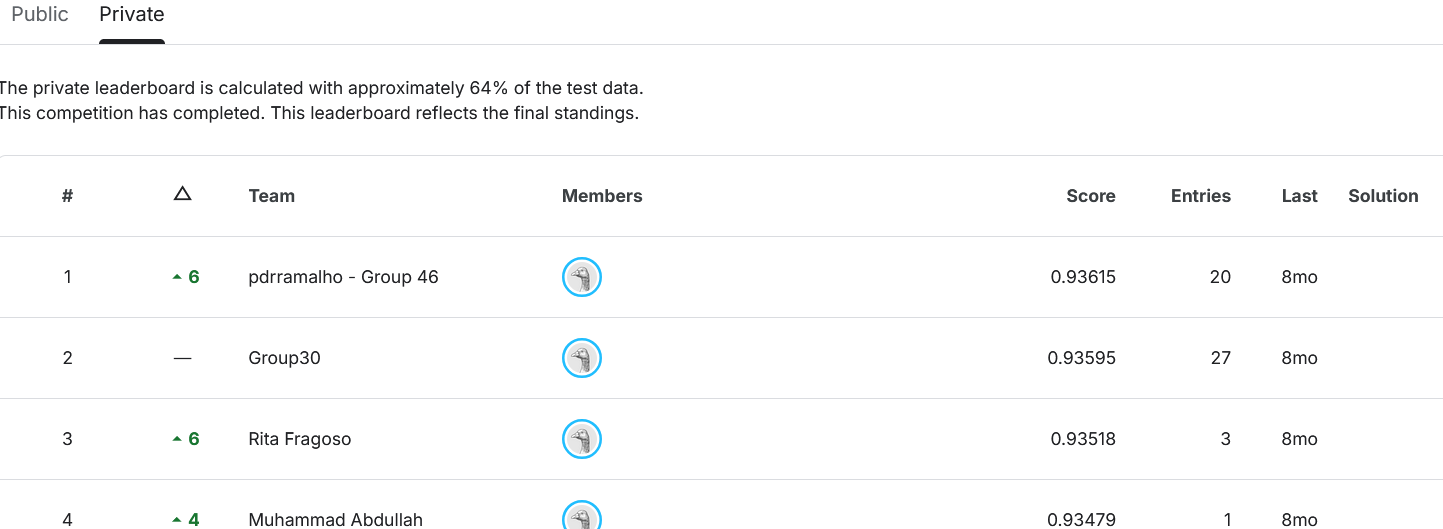

In [5]:
excel_path = r"C:\Users\Pedro Salgado\Documents\DA\WWW2025\FAI 2425 WWW Database.xls"

traindf = pd.read_excel(excel_path, sheet_name="Mail")
testdf = pd.read_excel(excel_path, sheet_name="BD")

In [6]:
traindf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Custid    2000 non-null   int64
 1   Dayswus   2000 non-null   int64
 2   Age       2000 non-null   int64
 3   Edu       2000 non-null   int64
 4   Income    2000 non-null   int64
 5   Freq      2000 non-null   int64
 6   Recency   2000 non-null   int64
 7   Monetary  2000 non-null   int64
 8   Spcork    2000 non-null   int64
dtypes: int64(9)
memory usage: 140.8 KB


In [7]:
testdf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Custid    8000 non-null   int64
 1   Dayswus   8000 non-null   int64
 2   Age       8000 non-null   int64
 3   Edu       8000 non-null   int64
 4   Income    8000 non-null   int64
 5   Freq      8000 non-null   int64
 6   Recency   8000 non-null   int64
 7   Monetary  8000 non-null   int64
dtypes: int64(8)
memory usage: 500.1 KB


No missing values, all integers - very easy dataset, normal since it was a 1st year project

In [8]:
original_traindf = traindf.copy()
original_testdf = testdf.copy()

In [9]:
# Basic descriptive statistics for numeric columns
traindf.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Custid,2000.0,6035.07,2893.34,1005.0,3540.50,5961.5,8596.25,11000.0
Dayswus,2000.0,895.90,203.69,550.0,724.75,893.5,1069.00,1249.0
Age,2000.0,47.53,17.56,18.0,33.00,48.0,63.00,78.0
Edu,2000.0,16.75,1.90,12.0,15.00,17.0,18.00,20.0
Income,2000.0,69622.94,27901.30,10000.0,47013.75,69335.0,92510.00,140628.0
Freq,2000.0,14.51,12.10,1.0,4.00,11.0,24.00,50.0
Recency,2000.0,63.52,75.55,0.0,26.00,52.0,77.00,549.0
Monetary,2000.0,618.75,653.58,8.0,63.00,341.5,1081.25,2704.0
Spcork,2000.0,0.07,0.26,0.0,0.00,0.0,0.00,1.0


In [10]:
counts = traindf['Spcork'].value_counts()

zeros = counts.get(0, 0)
ones = counts.get(1, 0)

print(f"{zeros} people did not buy the cork screw, {ones} people bought it. A total of {ones/2000*100} % of people bought the corkscrew.")

1855 people did not buy the cork screw, 145 people bought it. A total of 7.249999999999999 % of people bought the corkscrew.


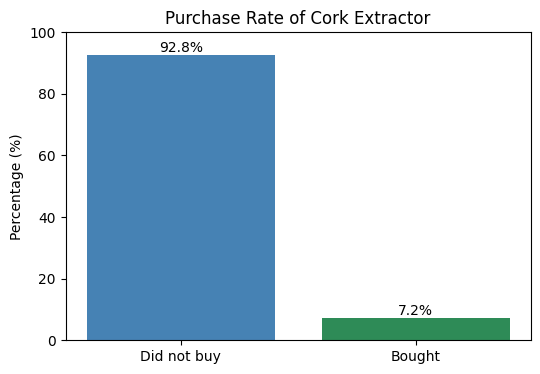

In [11]:
# Value counts in percentages
percentages = traindf['Spcork'].value_counts(normalize=True) * 100

# Reindex to ensure order: 0 = did not buy, 1 = bought
percentages = percentages.reindex([0, 1])

# Plot
plt.figure(figsize=(6, 4))
plt.bar(['Did not buy', 'Bought'], percentages, color=['steelblue', 'seagreen'])

# Labels
plt.ylabel('Percentage (%)')
plt.title('Purchase Rate of Cork Extractor')

# Add percentage labels on bars
for i, value in enumerate(percentages):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center')

plt.ylim(0, 100)
plt.show()

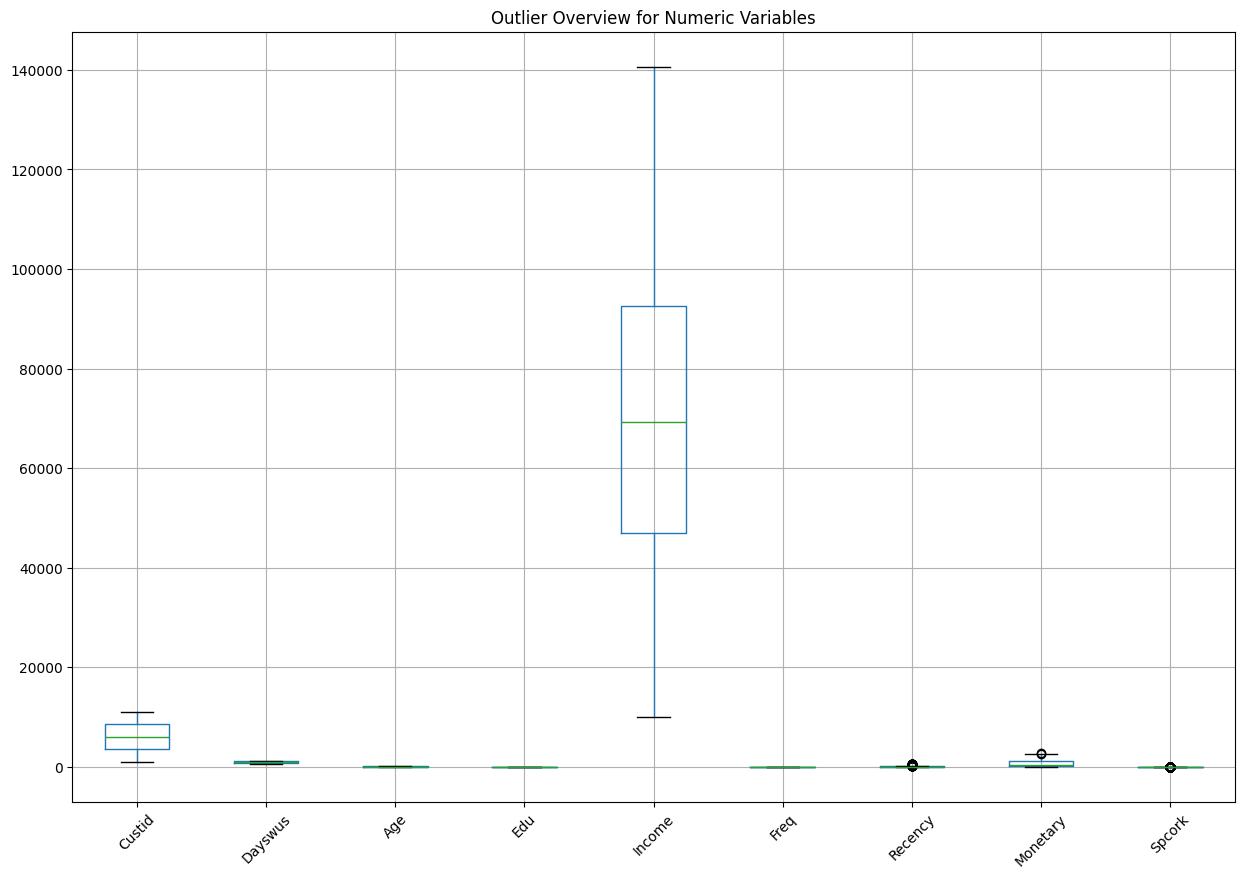

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,10))
traindf.boxplot()
plt.xticks(rotation=45)
plt.title("Outlier Overview for Numeric Variables")
plt.show()

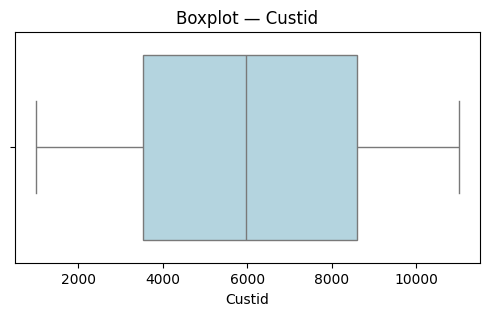

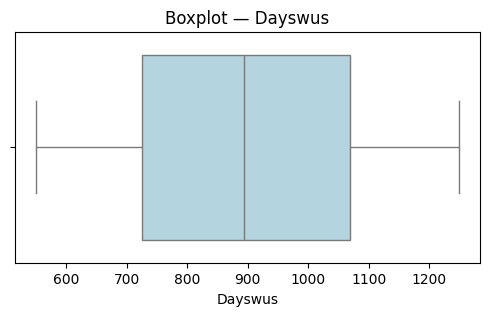

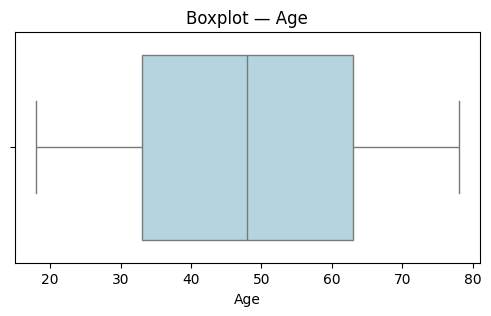

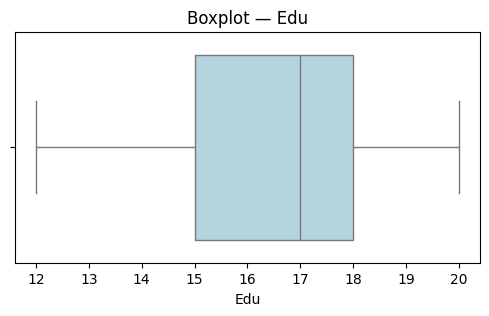

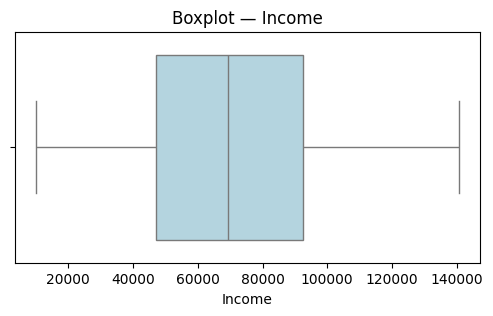

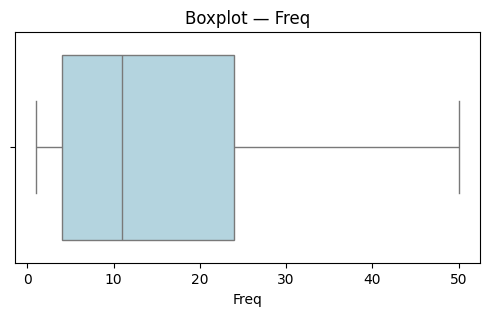

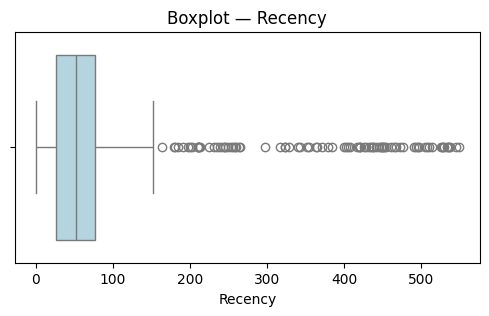

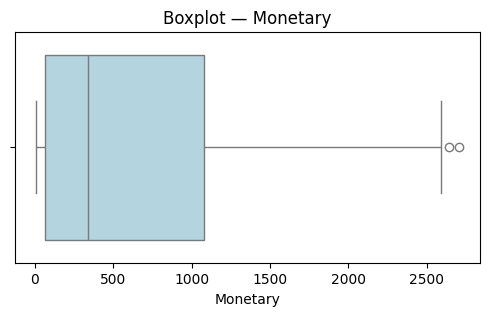

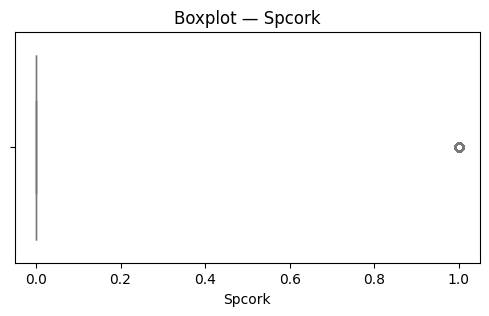

In [13]:
# Separate boxplots per variable for detailed visual analysis
import seaborn as sns

for col in traindf:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=traindf[col], color='lightblue')
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.show()

Recency is very right-skewed. Should be log transformed. Analyse graph first.

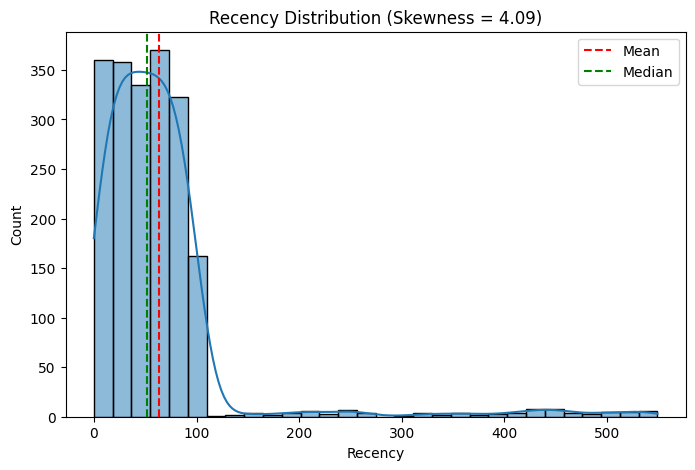

In [14]:
from scipy.stats import skew
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# calculate skewness
skew_val = skew(traindf['Recency'].dropna())

# plot distribution
plt.figure(figsize=(8, 5))
sns.histplot(traindf['Recency'], bins=30, kde=True)

plt.axvline(traindf['Recency'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(traindf['Recency'].median(), color='green', linestyle='--', label='Median')

plt.title(f"Recency Distribution (Skewness = {skew_val:.2f})")
plt.xlabel("Recency")
plt.ylabel("Count")
plt.legend()

plt.show()

In [15]:
display(traindf.sort_values(by='Recency', ascending=False).head(20))

,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,Spcork
518,3625,697,44,15,54727,1,549,14,0
811,5079,740,28,15,34246,1,546,8,0
81,1422,669,25,18,34304,1,538,12,0
593,4008,772,22,16,28095,1,537,9,0
1123,6617,620,30,16,47302,1,535,13,0
185,1940,1171,39,17,41558,1,534,19,0
1672,9444,722,34,20,58870,1,530,20,0
805,5033,846,20,14,30424,1,529,12,0
619,4137,729,33,18,44301,1,527,14,0
1549,8861,1185,22,16,31313,1,526,17,0


In [16]:
display(traindf.sort_values(by='Monetary', ascending=False).head(20))

,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,Spcork
1269,7341,836,77,16,132540,50,90,2704,1
344,2785,914,77,17,121510,49,8,2644,1
1434,8210,1055,68,17,113976,48,99,2589,1
1492,8554,1074,77,15,140628,48,36,2589,1
1131,6658,1195,71,18,105060,48,84,2589,0
1649,9355,1120,67,19,110811,47,91,2530,1
1751,9823,1175,69,19,107589,47,27,2530,1
1591,9039,1244,75,15,112534,46,33,2471,0
539,3758,1243,75,17,114985,46,62,2468,1
560,3866,729,77,18,126546,46,32,2468,1


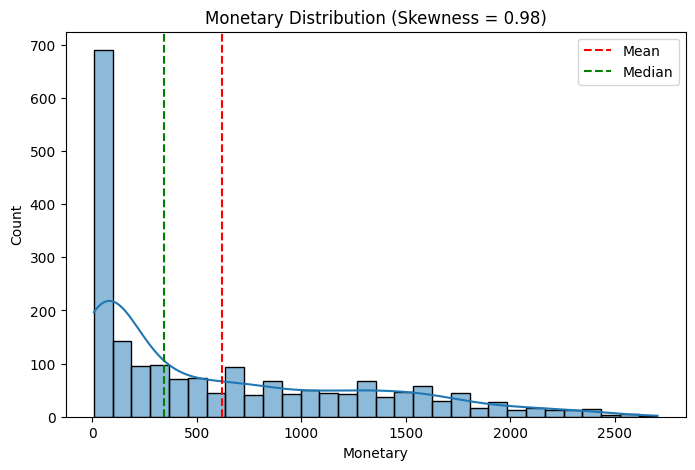

In [17]:

# calculate skewness
skew_val = skew(traindf['Monetary'].dropna())

# plot distribution
plt.figure(figsize=(8, 5))
sns.histplot(traindf['Monetary'], bins=30, kde=True)

plt.axvline(traindf['Monetary'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(traindf['Monetary'].median(), color='green', linestyle='--', label='Median')

plt.title(f"Monetary Distribution (Skewness = {skew_val:.2f})")
plt.xlabel("Monetary")
plt.ylabel("Count")
plt.legend()

plt.show()

Skewness is acceptable no need to touch maybe compare results with and without log transformation

In [18]:
# Log-transform Recency 
traindf['Recency'] = np.log1p(traindf['Recency'])
testdf['Recency'] = np.log1p(testdf['Recency'])

# Cap Monetary at 2589 - not definitive
traindf['Monetary'] = traindf['Monetary'].clip(upper=2589)
testdf['Monetary'] = testdf['Monetary'].clip(upper=2589)

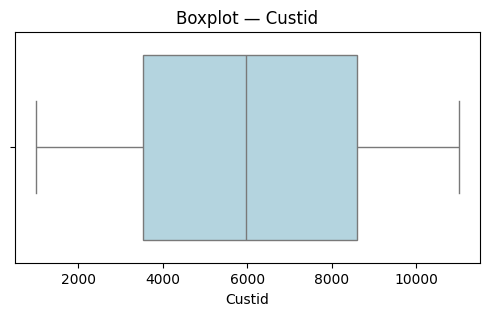

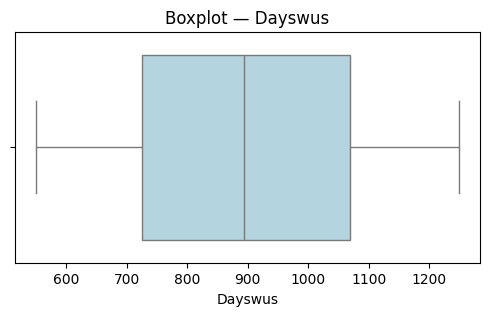

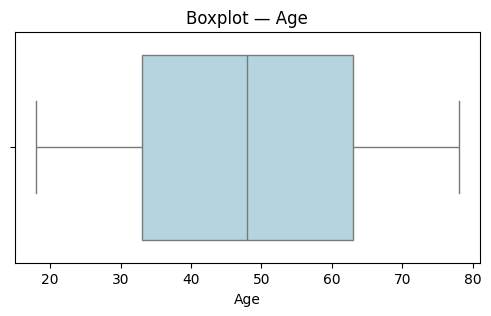

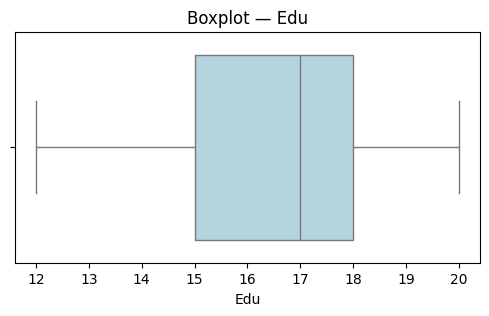

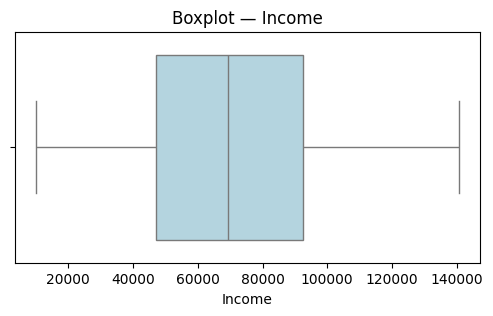

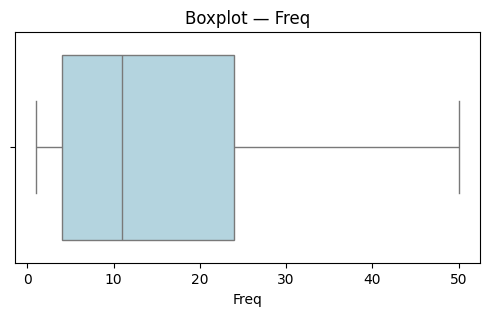

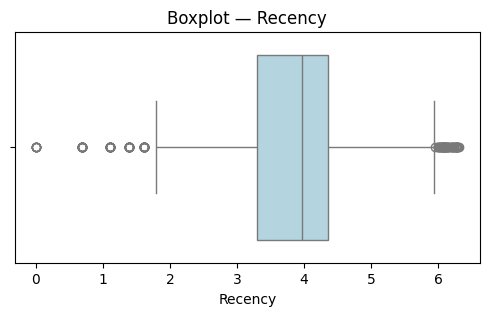

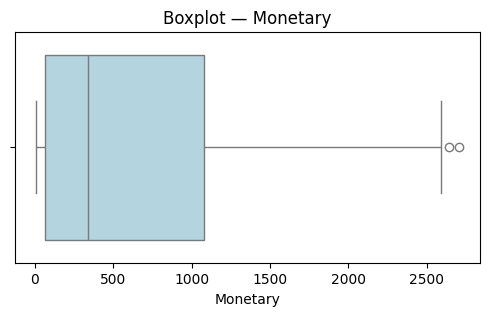

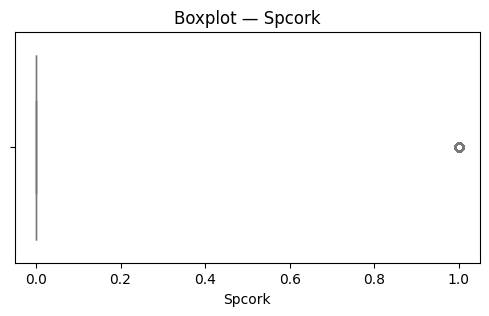

In [19]:
# Separate boxplots per variable for detailed visual analysis
import seaborn as sns

for col in traindf:
    plt.figure(figsize=(6,3))
    sns.boxplot(x=traindf[col], color='lightblue')
    plt.title(f"Boxplot — {col}")
    plt.xlabel(col)
    plt.show()

Better outlier distribuition

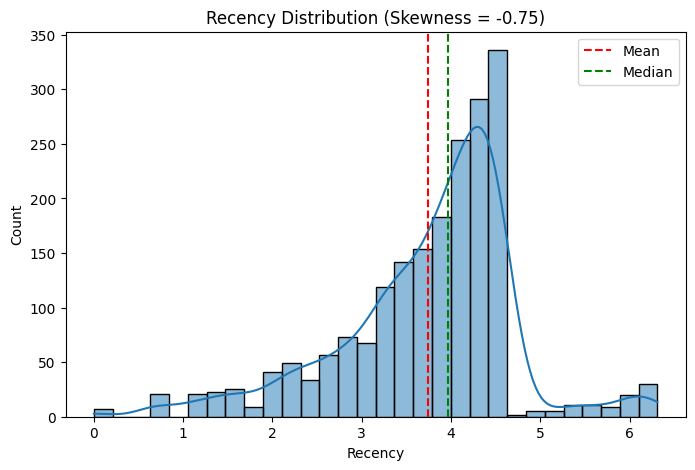

In [20]:

skew_val = skew(traindf['Recency'].dropna())

plt.figure(figsize=(8, 5))
sns.histplot(traindf['Recency'], bins=30, kde=True)

plt.axvline(traindf['Recency'].mean(), color='red', linestyle='--', label='Mean')
plt.axvline(traindf['Recency'].median(), color='green', linestyle='--', label='Median')

plt.title(f"Recency Distribution (Skewness = {skew_val:.2f})")
plt.xlabel("Recency")
plt.ylabel("Count")
plt.legend()

plt.show()

In [21]:
# Skewness before log (using copy)
before_skew = original_traindf['Recency'].skew()

# Skewness after log (current traindf)
after_skew = traindf['Recency'].skew()

print(f"Recency skewness before log: {before_skew:.3f}")
print(f"Recency skewness after log:  {after_skew:.3f}")

Recency skewness before log: 4.098
Recency skewness after log:  -0.749


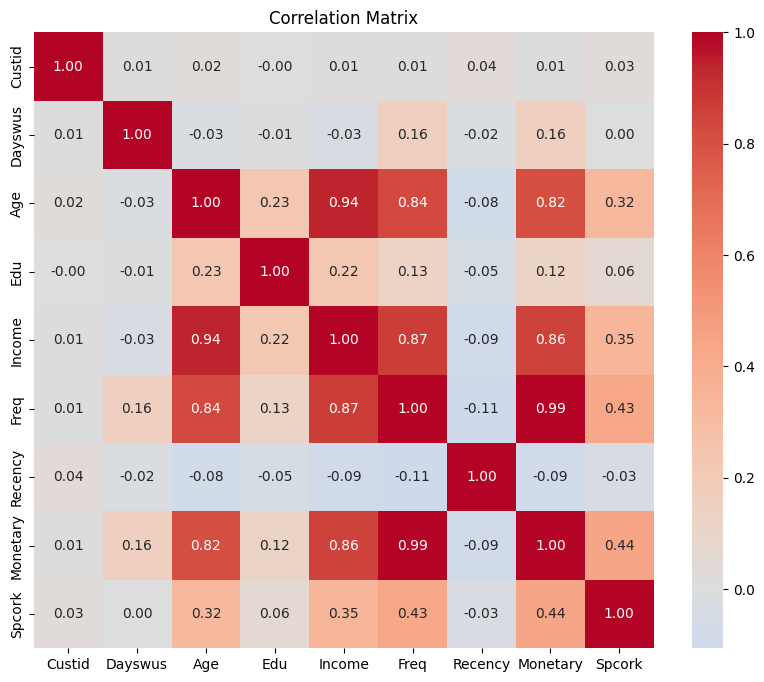

In [22]:
# Correlation matrix
corr_matrix = traindf.corr(numeric_only=True)

# Plot
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix")
plt.show()

Monetary, Freq are the most correlated variables to Spcork, followed by income and age. Dayswus ( days since first purchase) has absolutely no correlation to the target variable (0.00)

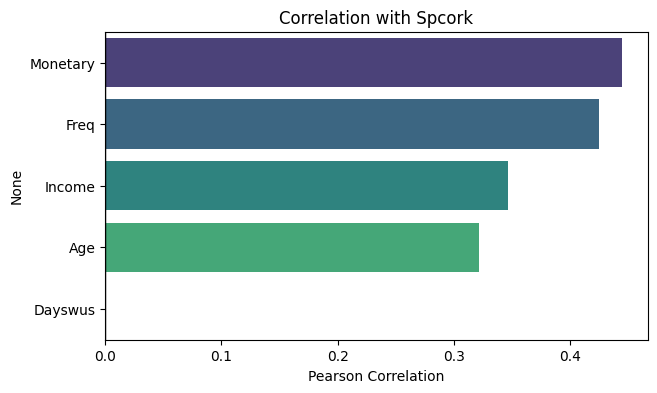

In [23]:
target = 'Spcork'
features = ['Monetary', 'Freq', 'Income', 'Age', 'Dayswus']

corrs = traindf[features + [target]].corr()[target].drop(target)

plt.figure(figsize=(7,4))
sns.barplot(
    x=corrs.values,
    y=corrs.index,
    palette='viridis'
)

plt.title('Correlation with Spcork')
plt.xlabel('Pearson Correlation')
plt.axvline(0, color='black', linewidth=1)
plt.show()

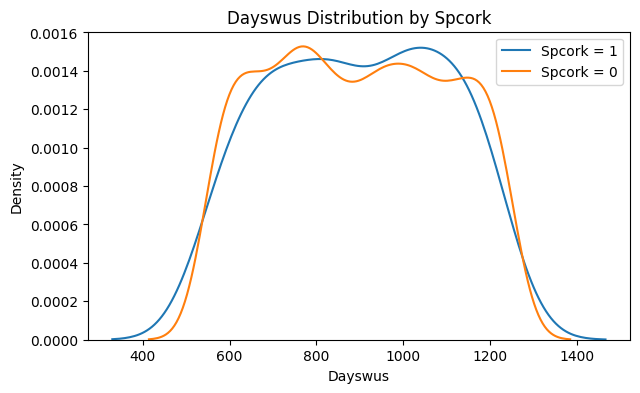

In [24]:
plt.figure(figsize=(7,4))
sns.kdeplot(traindf.loc[traindf['Spcork']==1, 'Dayswus'], label='Spcork = 1')
sns.kdeplot(traindf.loc[traindf['Spcork']==0, 'Dayswus'], label='Spcork = 0')

plt.title('Dayswus Distribution by Spcork')
plt.xlabel('Dayswus')
plt.legend()
plt.show()

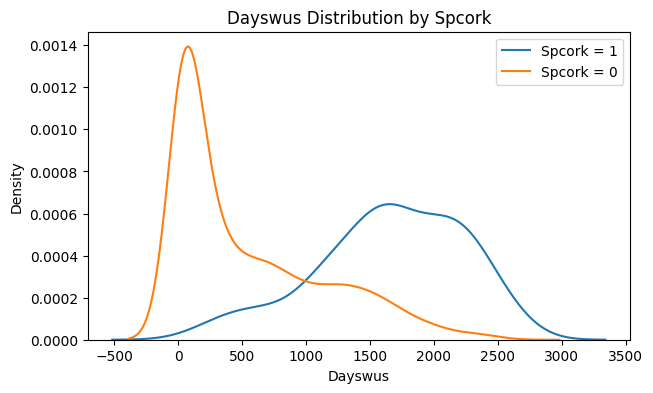

In [25]:
plt.figure(figsize=(7,4))
sns.kdeplot(traindf.loc[traindf['Spcork']==1, 'Monetary'], label='Spcork = 1')
sns.kdeplot(traindf.loc[traindf['Spcork']==0, 'Monetary'], label='Spcork = 0')

plt.title('Dayswus Distribution by Spcork')
plt.xlabel('Dayswus')
plt.legend()
plt.show()

In [26]:
# Basic descriptive statistics for numeric columns
traindf.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Custid,2000.0,6035.07,2893.34,1005.0,3540.50,5961.50,8596.25,11000.00
Dayswus,2000.0,895.90,203.69,550.0,724.75,893.50,1069.00,1249.00
Age,2000.0,47.53,17.56,18.0,33.00,48.00,63.00,78.00
Edu,2000.0,16.75,1.90,12.0,15.00,17.00,18.00,20.00
Income,2000.0,69622.94,27901.30,10000.0,47013.75,69335.00,92510.00,140628.00
Freq,2000.0,14.51,12.10,1.0,4.00,11.00,24.00,50.00
Recency,2000.0,3.74,0.99,0.0,3.30,3.97,4.36,6.31
Monetary,2000.0,618.75,653.58,8.0,63.00,341.50,1081.25,2704.00
Spcork,2000.0,0.07,0.26,0.0,0.00,0.00,0.00,1.00


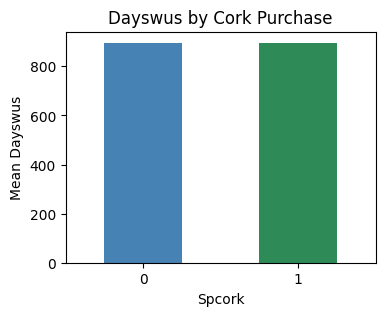

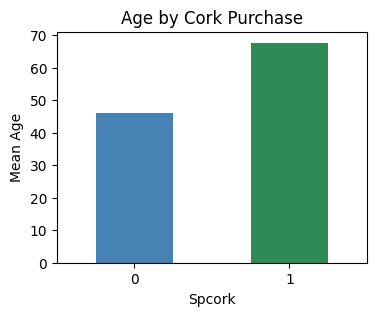

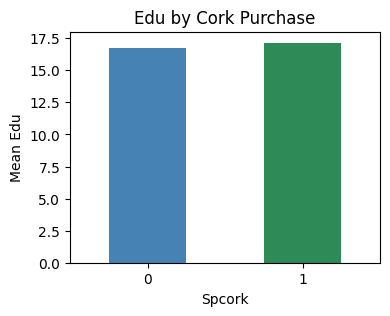

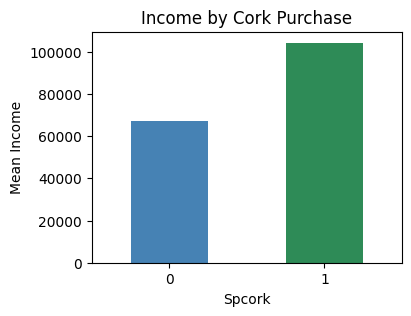

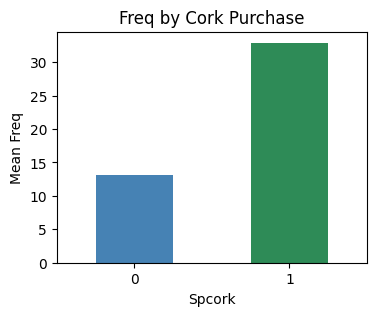

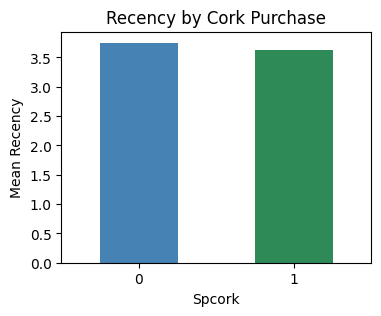

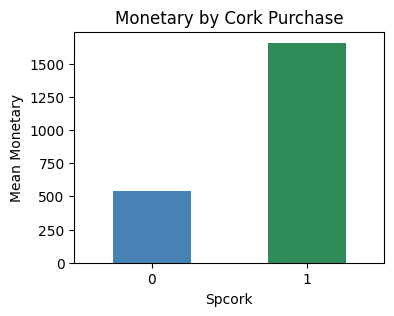

In [27]:
vars_to_plot = ['Dayswus', 'Age', 'Edu', 'Income', 'Freq', 'Recency', 'Monetary']

for col in vars_to_plot:
    plt.figure(figsize=(4, 3))
    traindf.groupby('Spcork')[col].mean().plot(
        kind='bar',
        color=['steelblue', 'seagreen']
    )
    plt.title(f'{col} by Cork Purchase')
    plt.ylabel(f'Mean {col}')
    plt.xticks(rotation=0)
    plt.show()

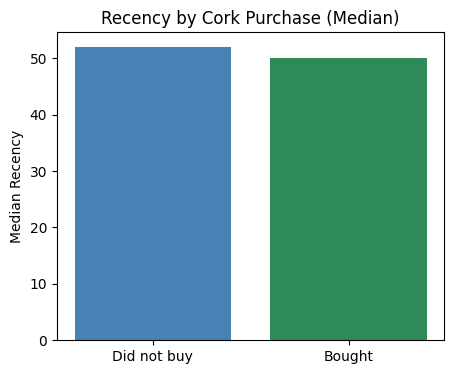

In [28]:
# Bar chart of median original Recency by Spcork
recency_median = original_traindf.groupby('Spcork')['Recency'].median()

plt.figure(figsize=(5, 4))
plt.bar(['Did not buy', 'Bought'], recency_median, color=['steelblue', 'seagreen'])
plt.ylabel('Median Recency')
plt.title('Recency by Cork Purchase (Median)')
plt.show()

In [29]:
# median comparison by Spcork
vars_to_check = [
    'Dayswus', 'Age', 'Edu', 'Income',
    'Freq', 'Recency', 'Monetary'
]

median_table = (
    traindf
    .groupby('Spcork')[vars_to_check]
    .median()
    .T
)

print(median_table)

Spcork               0              1
Dayswus     893.000000     902.000000
Age          45.000000      69.000000
Edu          17.000000      17.000000
Income    65908.000000  105855.000000
Freq         10.000000      33.000000
Recency       3.970292       3.931826
Monetary    294.000000    1668.000000


Customers who purchased the Cork Extractor have a median income 61% higher, make 230% more purchases, and generate 467% higher total monetary value than non‑purchasers; they are 53% older on average, have been customers for about 1% longer, show virtually no difference in education (0%), and exhibit nearly identical recency of purchase (about 1% difference).

In [30]:
traindf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Custid    2000 non-null   int64  
 1   Dayswus   2000 non-null   int64  
 2   Age       2000 non-null   int64  
 3   Edu       2000 non-null   int64  
 4   Income    2000 non-null   int64  
 5   Freq      2000 non-null   int64  
 6   Recency   2000 non-null   float64
 7   Monetary  2000 non-null   int64  
 8   Spcork    2000 non-null   int64  
dtypes: float64(1), int64(8)
memory usage: 140.8 KB


In [31]:
print(traindf.shape)     
print(traindf.columns)    # column
traindf.head()

(2000, 9)
Index(['Custid', 'Dayswus', 'Age', 'Edu', 'Income', 'Freq', 'Recency',
       'Monetary', 'Spcork'],
      dtype='object')


,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,Spcork
0,1005,1062,59,18,91852,25,3.295837,1138,1
1,1014,619,35,18,57997,5,3.367296,81,0
2,1015,1133,32,20,50289,1,5.446737,20,0
3,1017,624,22,16,20043,2,3.637586,16,0
4,1018,940,76,15,112765,39,4.290459,2039,0


Feature Engineering ideas



monetary / freq
average days per purchase - daysus / freq
percentage of income spent on products - income / monetary * 100 although this wont be accurate as no timeline but still might have a predictive power
customer value - monetary * 0,5 + freq + 0,3 + dayswus * 0.1 + recency * 0.1 ( i want this in a scale but since it will be normalized is ok)
Purchase Intensity - Freq / Dayswus
lifetime value - Monetary / Dayswus
Customer Maturity - Binary: Dayswus > median(Dayswus)

In [32]:
eps = 1e-6

for df in (traindf, testdf):
    df['avg_spend_per_purchase'] = df['Monetary'] / (df['Freq'] + eps)
    df['avg_days_per_purchase'] = df['Dayswus'] / (df['Freq'] + eps)
    df['pct_income_spent'] = (df['Monetary'] / (df['Income'] + eps)) * 100
    df['customer_value'] = (df['Monetary'] * 0.5 + df['Freq'] * 0.3 + df['Dayswus'] * 0.1 + df['Recency'] * 0.1)
    df['purchase_intensity'] = df['Freq'] / (df['Dayswus'] + eps)
    df['lifetime_value'] = df['Monetary'] / (df['Dayswus'] + eps)
# AI features
for df in (traindf, testdf):
    df['recency_ratio'] = df['Recency'] / (df['Dayswus'] + eps)
    df['monetary_recency'] = df['Monetary'] / (df['Recency'] + eps)
    df['income_per_edu'] = df['Income'] / (df['Edu'] + eps)
    df['age_income'] = df['Age'] * df['Income']
    df['engagement'] = df['Freq'] * df['Monetary'] / (df['Recency'] + eps)
    df['recency_freq_ratio'] = df['Recency'] / (df['Freq'] + eps)


In [33]:
traindf.head()

,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,Spcork,avg_spend_per_purchase,...,pct_income_spent,customer_value,purchase_intensity,lifetime_value,recency_ratio,monetary_recency,income_per_edu,age_income,engagement,recency_freq_ratio
0,1005,1062,59,18,91852,25,3.295837,1138,1,45.519998,...,1.238950,683.029584,0.023540,1.071563,0.003103,345.283975,5102.888605,5419268,8632.099380,0.131833
1,1014,619,35,18,57997,5,3.367296,81,0,16.199997,...,0.139662,104.236730,0.008078,0.130856,0.005440,24.054903,3222.055377,2029895,120.274517,0.673459
2,1015,1133,32,20,50289,1,5.446737,20,0,19.999980,...,0.039770,124.144674,0.000883,0.017652,0.004807,3.671922,2514.449874,1609248,3.671922,5.446732
3,1017,624,22,16,20043,2,3.637586,16,0,7.999996,...,0.079828,71.363759,0.003205,0.025641,0.005829,4.398520,1252.687422,440946,8.797040,1.818792
4,1018,940,76,15,112765,39,4.290459,2039,0,52.282050,...,1.808185,1125.629046,0.041489,2.169149,0.004564,475.240368,7517.666165,8570140,18534.374362,0.110012


In [34]:
testdf.head()

,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,avg_spend_per_purchase,avg_days_per_purchase,pct_income_spent,customer_value,purchase_intensity,lifetime_value,recency_ratio,monetary_recency,income_per_edu,age_income,engagement,recency_freq_ratio
0,1001,789,68,16,90782,29,4.204693,1402,48.344826,27.206896,1.544359,789.020469,0.036755,1.776933,0.005329,333.436899,5673.874645,6173176,9669.670059,0.144989
1,1002,623,78,20,113023,31,1.945910,1537,49.580644,20.096774,1.359900,840.294591,0.049759,2.467095,0.003123,789.861346,5651.149717,8815794,24485.701736,0.062771
2,1003,583,24,18,28344,4,4.248495,44,10.999997,145.749964,0.155236,81.924850,0.006861,0.075472,0.007287,10.356606,1574.666579,680256,41.426422,1.062124
3,1004,893,59,19,93571,21,2.397895,888,42.285712,42.523807,0.949012,539.839790,0.023516,0.994401,0.002685,370.324609,4924.789214,5520689,7776.816792,0.114185
4,1006,792,32,20,22386,5,4.189655,56,11.199998,158.399968,0.250156,109.118965,0.006313,0.070707,0.005290,13.366253,1119.299944,716352,66.831267,0.837931


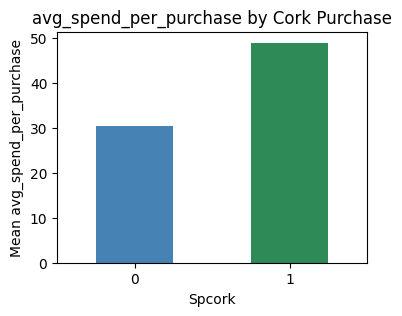

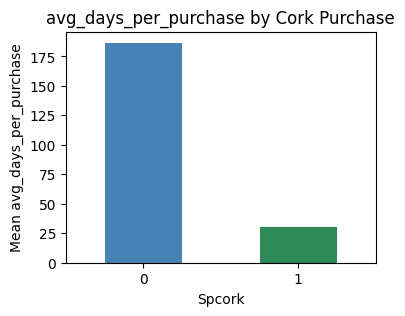

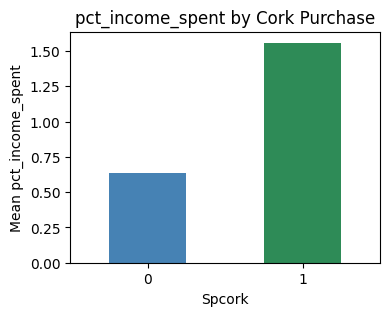

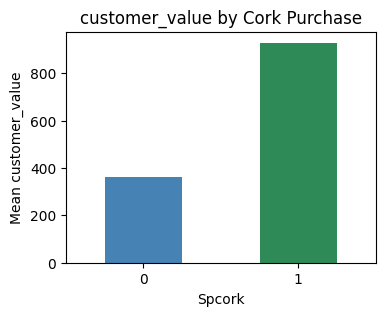

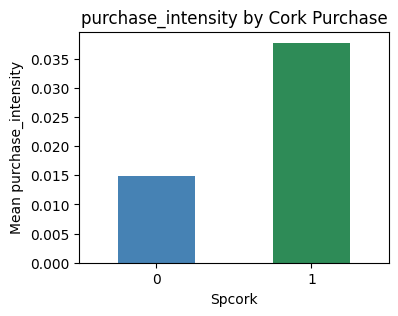

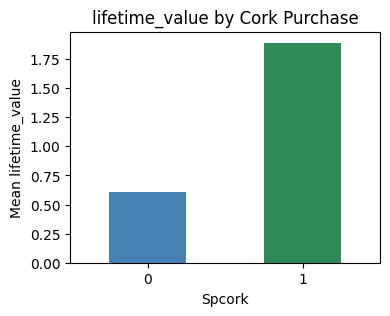

In [35]:
# Bar charts (mean of each variable by Spcork)
vars_to_plot = ['avg_spend_per_purchase', 'avg_days_per_purchase', 'pct_income_spent', 'customer_value', 'purchase_intensity', 'lifetime_value']

for col in vars_to_plot:
    plt.figure(figsize=(4, 3))
    traindf.groupby('Spcork')[col].mean().plot(
        kind='bar',
        color=['steelblue', 'seagreen']
    )
    plt.title(f'{col} by Cork Purchase')
    plt.ylabel(f'Mean {col}')
    plt.xticks(rotation=0)
    plt.show()

In [36]:
from sklearn.preprocessing import StandardScaler

# Columns to normalize (exclude target variable Spcork)
features = traindf.columns.drop('Spcork')

scaler = StandardScaler()

# Fit on train only to prevent data leakage, transform both
traindf[features] = scaler.fit_transform(traindf[features])
testdf[features]  = scaler.transform(testdf[features])

In [37]:
traindf.head()


,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,Spcork,avg_spend_per_purchase,...,pct_income_spent,customer_value,purchase_intensity,lifetime_value,recency_ratio,monetary_recency,income_per_edu,age_income,engagement,recency_freq_ratio
0,-1.738936,0.815676,0.653394,0.658132,0.796903,0.867419,-0.450672,0.794677,1,0.998565,...,0.902601,0.835841,0.495361,0.493394,-0.814617,-0.044712,0.559571,0.645195,-0.037839,-0.551304
1,-1.735825,-1.359735,-0.713480,0.658132,-0.416785,-0.786146,-0.378386,-0.822979,0,-1.131025,...,-0.936132,-0.896022,-0.599107,-0.754391,0.633122,-0.044721,-0.561559,-0.678393,-0.037851,-0.126943
2,-1.735479,1.164331,-0.884339,1.712408,-0.693114,-1.116859,1.725148,-0.916334,0,-0.855022,...,-1.103217,-0.836454,-1.108365,-0.904549,0.241185,-0.044722,-0.983349,-0.842661,-0.037851,3.612889
3,-1.734787,-1.335182,-1.453870,-0.396144,-1.777420,-1.034181,-0.104964,-0.922456,0,-1.726613,...,-1.036214,-0.994385,-0.943977,-0.893952,0.874509,-0.044722,-1.735462,-1.298896,-0.037851,0.770419
4,-1.734442,0.216579,1.621597,-0.923282,1.546625,2.024914,0.555474,2.173586,0,1.489711,...,1.854738,2.160187,1.765784,1.949268,0.090591,-0.044708,1.998974,1.875647,-0.037825,-0.568401


In [38]:
testdf.head()

,Custid,Dayswus,Age,Edu,Income,Freq,Recency,Monetary,avg_spend_per_purchase,avg_days_per_purchase,pct_income_spent,customer_value,purchase_intensity,lifetime_value,recency_ratio,monetary_recency,income_per_edu,age_income,engagement,recency_freq_ratio
0,-1.740319,-0.524927,1.165972,-0.396144,0.758544,1.198132,0.468713,1.198708,1.203740,-0.677206,1.413447,1.152987,1.430712,1.429019,0.564496,-0.044712,0.899925,0.939605,-0.037838,-0.540996
1,-1.739973,-1.340093,1.735503,1.712408,1.555874,1.363488,-1.816239,1.405315,1.293501,-0.709723,1.104910,1.306409,2.351125,2.344473,-0.802208,-0.044698,0.886379,1.971578,-0.037817,-0.605414
2,-1.739627,-1.536518,-1.339964,0.658132,-1.479833,-0.868824,0.513023,-0.879604,-1.508715,-0.135074,-0.910083,-0.962784,-0.685210,-0.827855,1.777821,-0.044722,-1.543536,-1.205443,-0.037851,0.177573
3,-1.739282,-0.014221,0.653394,1.185270,0.858528,0.536706,-1.359017,0.412071,0.763650,-0.607157,0.417634,0.407389,0.493645,0.391043,-1.073752,-0.044711,0.453409,0.684801,-0.037840,-0.565131
4,-1.738590,-0.510195,-0.884339,1.712408,-1.693425,-0.786146,0.453501,-0.861239,-1.494188,-0.077222,-0.751313,-0.881414,-0.723992,-0.834175,0.540223,-0.044722,-1.814972,-1.191347,-0.037851,0.001919


In [39]:
# split the train_ds into features and target
 # X = traindf.drop(columns='Spcork')
# y = traindf['Spcork'].astype(int)

 # from sklearn.model_selection import train_test_split

# split the data into train and test sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [40]:
from sklearn.model_selection import StratifiedKFold

X = traindf.drop(columns=['Spcork', 'Custid'])
y = traindf['Spcork'].astype(int)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

StratifiedKFold: splits the data so that each fold preserves the class proportions of Spcork (important for a binary target).

n_splits=10: performs 10‑fold cross‑validation, meaning 90% of the data is used for training and 10% for validation in each iteration. This balances bias and variance well for most datasets. 
5 folds → ~29 positive cases per fold (safe)
10 folds → ~14 positives per fold  borderline, higher variance
Primary driver: total dataset size, not the Spcork percentage.
Constraint: class counts per fold must be sufficient (especially the minority class).


shuffle=True: randomly shuffles the data before splitting, preventing any ordering effects (for example, time‑ or ID‑based patterns).
random_state=42: fixes the random seed so the folds are reproducible across runs.
y cast to int: ensures the target is treated as a binary class label, which StratifiedKFold requires for proper stratification.
X definition: removes Spcork (target) and Custid (identifier with no predictive value) to avoid leakage and noise.

In [41]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

X = traindf.drop(columns=['Spcork', 'Custid'])
y = traindf['Spcork'].astype(int)

classifiers = [
    RandomForestClassifier(n_estimators=300, max_depth=6, class_weight='balanced', random_state=42),
    XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, eval_metric='logloss', verbosity=0, random_state=42),
    GradientBoostingClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42),
    LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    SVC(kernel='rbf', class_weight='balanced', random_state=42),
    KNeighborsClassifier(n_neighbors=5),
    GaussianNB(),
    DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
]

classifiers_names = ['RandomForest', 'XGBoost', 'GradientBoosting', 'LogisticRegression', 
                     'SVC', 'KNN', 'NaiveBayes', 'DecisionTree']

cv = StratifiedKFold(n_splits=10, random_state=42, shuffle=True)

for clf, name in zip(classifiers, classifiers_names):
    scores = cross_val_score(clf, X, y, cv=cv, scoring='accuracy')
    print(f"{name}: {scores.mean():.4f}")

RandomForest: 0.8850
XGBoost: 0.9215
GradientBoosting: 0.9185
LogisticRegression: 0.7830
SVC: 0.7820
KNN: 0.9230
NaiveBayes: 0.6310
DecisionTree: 0.8110


In [42]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
import pandas as pd

# Data
X = traindf.drop(columns=['Spcork', 'Custid'])
y = traindf['Spcork'].astype(int)
X_test = testdf.drop(columns=['Custid'])

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

from sklearn.ensemble import RandomForestClassifier

# Random Forest 
rf_params = {
    'n_estimators': [200, 300, 500],
    'max_depth': [4, 6, 8, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced']
}

rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    rf_params,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

rf_search.fit(X, y)
print(f"RandomForest Best: {rf_search.best_score_:.4f} | {rf_search.best_params_}")

rf_pred = rf_search.best_estimator_.predict(X_test)

# KNN
knn_params = {
    'n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

knn_search = GridSearchCV(KNeighborsClassifier(), knn_params, cv=cv, scoring='accuracy', n_jobs=-1)
knn_search.fit(X, y)
print(f"KNN Best: {knn_search.best_score_:.4f} | {knn_search.best_params_}")

knn_pred = knn_search.best_estimator_.predict(X_test)

# XGBoost
xgb_params = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_search = GridSearchCV(
    XGBClassifier(eval_metric='logloss', verbosity=0, random_state=42),
    xgb_params, cv=cv, scoring='accuracy', n_jobs=-1
)
xgb_search.fit(X, y)
print(f"XGBoost Best: {xgb_search.best_score_:.4f} | {xgb_search.best_params_}")

xgb_pred = xgb_search.best_estimator_.predict(X_test)

# Gradient Boosting - takes almost 20 minutes 
gb_params = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'min_samples_split': [2, 5, 10]
}

gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    gb_params, cv=cv, scoring='accuracy', n_jobs=-1
)
gb_search.fit(X, y)
print(f"GradientBoosting Best: {gb_search.best_score_:.4f} | {gb_search.best_params_}")

gb_pred = gb_search.best_estimator_.predict(X_test)


RandomForest Best: 0.9285 | {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 300}
KNN Best: 0.9290 | {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
XGBoost Best: 0.9280 | {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
GradientBoosting Best: 0.9270 | {'learning_rate': 0.01, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 100, 'subsample': 0.8}


In [43]:
# Submissions
pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': knn_pred}).to_csv('submission_knnnovoting.csv', index=False)
pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': xgb_pred}).to_csv('submission_xgbnovoting.csv', index=False)
pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': gb_pred}).to_csv('submission_gbnovoting.csv', index=False)
pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': rf_pred}).to_csv('submission_rfnovoting.csv', index=False)

I want to experiment in changing outlier treatment, number of samples

In [44]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[
        ('rf', rf_search.best_estimator_),
        ('gb', gb_search.best_estimator_),
        ('xgb', xgb_search.best_estimator_),
        ('knn', knn_search.best_estimator_)
    ],
    voting='hard'
)

ensemble.fit(X, y)
ensemble_pred = ensemble.predict(X_test)

pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': ensemble_pred}).to_csv('submission_ensemble.csv', index=False)

In [45]:
ensemble_soft = VotingClassifier(
    estimators=[
        ('rf', rf_search.best_estimator_),
        ('gb', gb_search.best_estimator_),
        ('xgb', xgb_search.best_estimator_),
        ('knn', knn_search.best_estimator_)
    ],
    voting='soft'
)

ensemble_soft.fit(X, y)
soft_pred = ensemble_soft.predict(X_test)

pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': soft_pred}).to_csv('submission_soft.csv', index=False)

In [46]:
ensemble_weighted = VotingClassifier(
    estimators=[
        ('rf', rf_search.best_estimator_),
        ('gb', gb_search.best_estimator_),
        ('xgb', xgb_search.best_estimator_),
        ('knn', knn_search.best_estimator_)
    ],
    voting='soft',
    weights=[2, 3, 1, 2]
)

ensemble_weighted.fit(X, y)
weighted_pred = ensemble_weighted.predict(X_test)

pd.DataFrame({'Custid': original_testdf['Custid'], 'Spcork': weighted_pred}).to_csv('submission_weighted.csv', index=False)

For 10 splits, capped monetary, log recency, ai features

| Submission File | Score |
|-----------------|-------|
| submission_gbnovoting.csv | 0.93324 |
| submission_knnnovoting.csv | 0.93634 |
| submission_xgbnovoting.csv | 0.93557 |
| submission_rfnovoting.csv | 0.93013 |
| submission_ensemble.csv | **0.93673** |
| submission_soft.csv | 0.93615 |
| submission_weighted.csv | 0.93595 |

Best score: `submission_ensemble.csv` with 0.93673

For 5 splits, capped monetary, log recency, ai features


| Submission File | Private Score |
|-----------------|---------------|
| submission_weighted.csv | 0.93401 |
| submission_soft.csv | 0.93460 |
| submission_ensemble.csv | 0.93498 |
| submission_gbnovoting.csv | 0.93304 |
| submission_knnnovoting.csv | 0.93324 |
| submission_rfnovoting.csv | 0.92916 |
| submission_xgbnovoting.csv | **0.93557** |

**Best private score:** `submission_xgbnovoting.csv` with **0.93557**


10 is better 

For 10 splits, capped monetary, log recency, no ai features



| Submission File | Private Score |
|-----------------|---------------|
| submission_xgbnovoting.csv | 0.93188 |
| submission_rfnovoting.csv | 0.92858 |
| submission_knnnovoting.csv | **0.93673** |
| submission_gbnovoting.csv | 0.93285 |
| submission_ensemble.csv | 0.93285 |
| submission_soft.csv | 0.93518 |
| submission_weighted.csv | 0.93537 |

**Best private score:** `submission_knnnovoting.csv` with **0.93673**

we'll keep the features

test w vs w/o mon, w vs w/o log recency, with a different stratification. we have already beaten the Kaggle top score multiple times

For 10 splits, NOT capped monetary, log recency,  ai features

| Submission File | Score |
|-----------------|-------|
| submission_weighted.csv | 0.93576 |
| submission_soft.csv | **0.93673** |
| submission_ensemble.csv | 0.93576 |
| submission_gbnovoting.csv | 0.93363 |
| submission_knnnovoting.csv | 0.93654 |
| submission_rfnovoting.csv | 0.93052 |
| submission_xgbnovoting.csv | 0.93479 |

**Best score:** `submission_soft.csv` with **0.93673**

Both have same highest results, NOT capped has superior results 4 vs 3. Similarity indicates the outlier treatment in Monetary was not necessary.

For 10 splits, NOT capped monetary, NOT log recency,  ai features


| Submission File | Private Score |
|-----------------|---------------|
| submission_xgbnovoting.csv | 0.93498 |
| submission_rfnovoting.csv | 0.93130 |
| submission_knnnovoting.csv | 0.93188 |
| submission_gbnovoting.csv | 0.93460 |
| submission_ensemble.csv | **0.93557** |
| submission_soft.csv | 0.93518 |
| submission_weighted.csv | **0.93557** |

**Best score (tie):**
- `submission_ensemble.csv` → **0.93557**
- `submission_weighted.csv` → **0.93557**


log recency improves results

For 10 splits, NOT capped monetary,  log recency,  ai features, different stratification


| Rank | Submission File | Private Score |
|-----:|-----------------|---------------|
| 1 | submission_soft.csv | **0.93673** |
| 2 | submission_knnnovoting.csv | 0.93654 |
| 3 | submission_ensemble.csv | 0.93576 |
| 3 | submission_weighted.csv | 0.93576 |
| 5 | submission_xgbnovoting.csv | 0.93479 |
| 6 | submission_gbnovoting.csv | 0.93363 |
| 7 | submission_rfnovoting.csv | 0.93052 |

- **Best model:**  `submission_soft.csv` with **0.93673**

I hit a wall no matter what at 0.93673 apparently. Regardless, that is number one in accuracy.


I did manage to enter 0.937 territory twice but did not register my exact parameters for the submission as I was still experimenting. Still, objective sucedeed, for a fairly easy dataset.
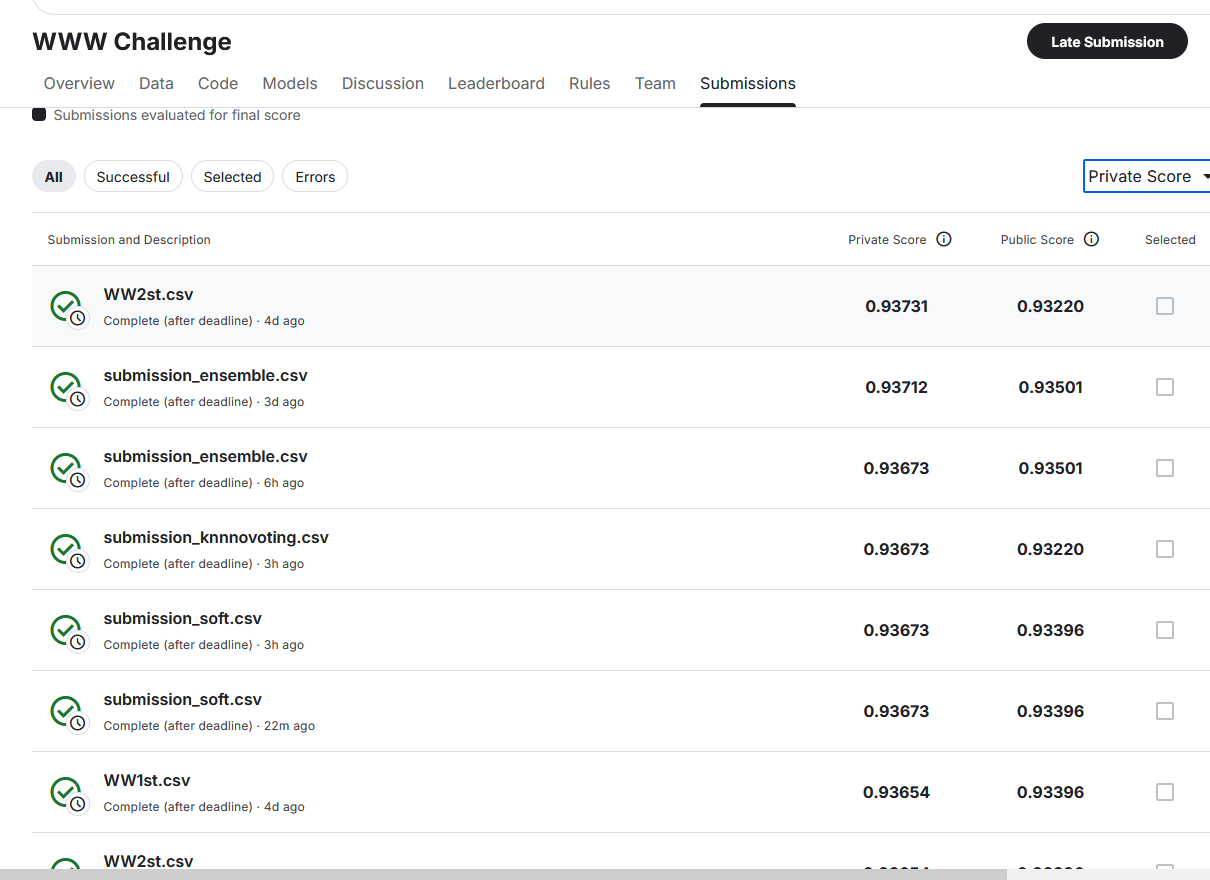

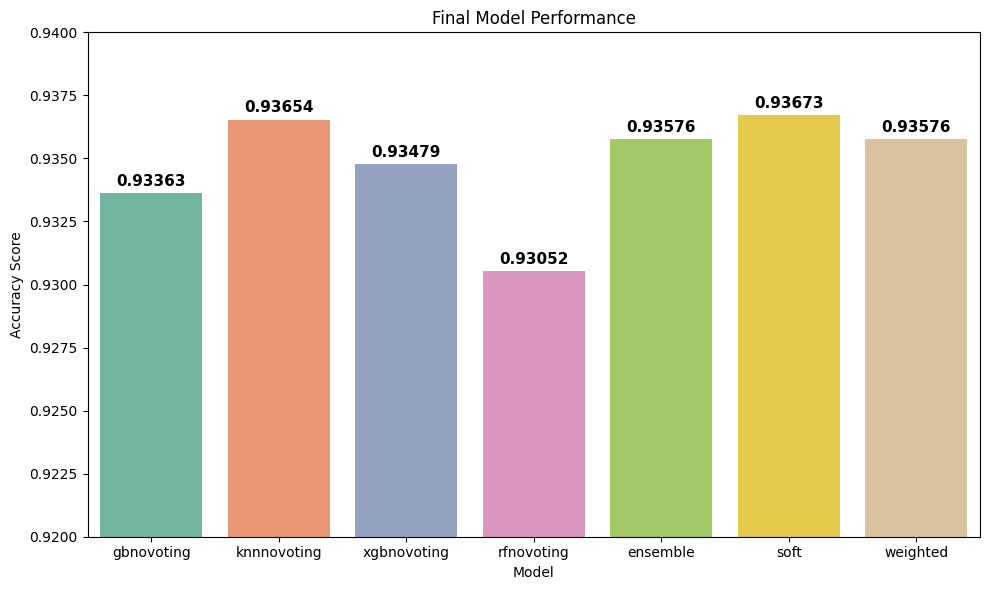

In [50]:
# Graph of final model performances (best accuracy setting)
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Use the best setting (10 splits, NOT capped monetary, log recency, ai features, different stratification)
final_results = {
    "Model": [
        "gbnovoting", "knnnovoting", "xgbnovoting", "rfnovoting", "ensemble", "soft", "weighted"
    ],
    "Score": [
        0.93363, 0.93654, 0.93479, 0.93052, 0.93576, 0.93673, 0.93576
    ]
}

final_df = pd.DataFrame(final_results)

plt.figure(figsize=(10, 6))
bar = sns.barplot(
    data=final_df,
    x="Model",
    y="Score",
    palette="Set2"
)
plt.title("Final Model Performance")
plt.ylabel("Accuracy Score")
plt.ylim(0.92, 0.94)
plt.xlabel("Model")

# Add accuracy labels on all bars
for p in bar.patches:
    bar.annotate(f'{p.get_height():.5f}',
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=11, fontweight='bold', color='black',
                 xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()
